# Simulation mimiSBM : association des clusters Ka et Distance

Protocole de simulation restreint à **deux descripteurs : Ka et Distance**.

1. On charge les matrices d'adjacence de référence de Ka et Distance (clusters K-means).
2. On simule **5 matrices par descripteur** en perturbant les clusters (réaffectation aléatoire de 0,5 % des paires, via `permute_adjacency_labels`).
3. On empile les 10 vues en un tenseur N×N×10 et on ajuste `MimiSBM` avec **Q = 2** composantes (Ka / Distance).
4. Le K attendu est le nombre de couples (cluster_ka, cluster_dist) non vides : chaque cluster final doit correspondre à un couple de clusters liés  
   (K_final = 1 ↔ cluster_1_ka & cluster_1_dist, K_final = 2 ↔ cluster_1_ka & cluster_2_dist, etc.).

## Imports et configuration

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

repo_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "mimisbm_main" / "mimisbm" / "_base.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Introuvable : mimisbm_main/mimisbm/_base.py")
sys.path.insert(0, str(repo_root))
from mimisbm_main.mimisbm._base import MimiSBM

# Données (mêmes matrices que le notebook simu_ge_kaks)
FAMILY_DIR = repo_root.parent / "Données" / "adjacency" / "lda" / "family"
PATHS = {
    "Ka": FAMILY_DIR / "adjacency_matrix_silh_Ka.csv",
    "Distance": FAMILY_DIR / "adjacency_matrix_silh_Distance.csv",
}

# Protocole de simulation
N_COPIES = 5            # matrices simulées par descripteur
TAUX_PERTURBATION = 0.005   # 0,5 % des paires réaffectées dans un autre cluster
SEED = 0

# Modèle
Q = 2                   # une composante par descripteur
N_INIT = 10             # multi-restarts manuels (meilleur ELBO)
PRIORS = "jeffreys"
MAX_ITER = 100
TOL = 1e-6

OUTPUT_DIR = Path("simulation_ka_distance")
OUTPUT_DIR.mkdir(exist_ok=True)

## Chargement, labels de clusters et perturbation

In [2]:
def charger_matrice(path):
    """Matrice d'adjacence binaire, symétrique, diagonale nulle."""
    m = pd.read_csv(path, index_col=0).to_numpy()
    if m.ndim != 2 or m.shape[0] != m.shape[1]:
        raise ValueError(f"{path.name}: matrice non carrée {m.shape}")
    if not np.all(np.isin(np.unique(m), [0, 1])):
        raise ValueError(f"{path.name}: valeurs hors de {{0, 1}}")
    m = m.astype(np.int64)
    np.fill_diagonal(m, 0)
    return np.maximum(m, m.T)


def adjacence_vers_labels(adjacency):
    """Labels de clusters : les lignes identiques de A (+ diagonale) forment un cluster."""
    same = np.maximum(adjacency, adjacency.T).astype(bool)
    np.fill_diagonal(same, True)
    _, labels = np.unique(same, axis=0, return_inverse=True)
    return labels.ravel()


def labels_vers_adjacence(labels):
    A = (labels[:, None] == labels[None, :]).astype(np.int64)
    np.fill_diagonal(A, 0)
    return A


def perturber_labels(labels, taux, rng):
    """Réaffecte aléatoirement round(taux * N) paires dans un autre cluster."""
    labels = labels.copy()
    clusters = np.unique(labels)
    n_changes = round(taux * len(labels))
    for i in rng.choice(len(labels), size=n_changes, replace=False):
        labels[i] = rng.choice(clusters[clusters != labels[i]])
    return labels


ref = {nom: charger_matrice(p) for nom, p in PATHS.items()}
labels_ref = {nom: adjacence_vers_labels(A) for nom, A in ref.items()}
N = next(iter(ref.values())).shape[0]

for nom, lab in labels_ref.items():
    print(f"{nom} : {len(np.unique(lab))} clusters, tailles = {np.bincount(lab).tolist()}")
print(f"N = {N} paires, {round(TAUX_PERTURBATION * N)} paires réaffectées par matrice simulée")

Ka : 2 clusters, tailles = [306, 138]
Distance : 2 clusters, tailles = [107, 337]
N = 444 paires, 2 paires réaffectées par matrice simulée


## Vérité terrain : couples de clusters (cluster_ka, cluster_dist)

Chaque paire appartient à un cluster Ka et à un cluster Distance. Chaque couple **non vide** définit un cluster final attendu (numéroté 1, 2, … par ordre lexicographique).

In [3]:
lab_ka, lab_dist = labels_ref["Ka"], labels_ref["Distance"]

couples = (
    pd.DataFrame({"cluster_ka": lab_ka + 1, "cluster_dist": lab_dist + 1})
    .value_counts().rename("taille").reset_index()
    .sort_values(["cluster_ka", "cluster_dist"]).reset_index(drop=True)
)
couples.insert(0, "K_final", np.arange(1, len(couples) + 1))
K_VRAI = len(couples)
display(couples)
print(f"K attendu = {K_VRAI} couples non vides")

# Cluster final attendu de chaque paire
cle = {(r.cluster_ka, r.cluster_dist): r.K_final for r in couples.itertuples()}
z_vrai = np.array([cle[(a + 1, d + 1)] for a, d in zip(lab_ka, lab_dist)]) - 1

,K_final,cluster_ka,cluster_dist,taille
0,1,1,1,60
1,2,1,2,246
2,3,2,1,47
3,4,2,2,91


K attendu = 4 couples non vides


## Simulation des 5 matrices par descripteur et assemblage du tenseur

In [4]:
def simuler_tenseur(labels_ref, n_copies, taux, seed):
    rng = np.random.default_rng(seed)
    vues, noms = [], []
    for nom, labels in labels_ref.items():
        for c in range(n_copies):
            vues.append(labels_vers_adjacence(perturber_labels(labels, taux, rng)))
            noms.append(f"{nom}_{c + 1}")
    return np.stack(vues, axis=2), noms


tenseur, noms_vues = simuler_tenseur(labels_ref, N_COPIES, TAUX_PERTURBATION, SEED)
w_vrai = np.repeat(np.arange(len(labels_ref)), N_COPIES)   # composante vraie de chaque vue
print("Tenseur :", tenseur.shape)
print("Vues    :", noms_vues)

Tenseur : (444, 444, 10)
Vues    : ['Ka_1', 'Ka_2', 'Ka_3', 'Ka_4', 'Ka_5', 'Distance_1', 'Distance_2', 'Distance_3', 'Distance_4', 'Distance_5']


## Ajustement de MimiSBM (K = nombre de couples, Q = 2)

In [5]:
def ajuster_meilleur_elbo(tenseur, k, q, n_init=N_INIT, seed0=SEED):
    meilleur = None
    for init in range(n_init):
        modele = MimiSBM(
            n_clusters=k, n_components=q,
            clusters_prior=PRIORS, components_prior=PRIORS, adjacency_prior=PRIORS,
            max_iter=MAX_ITER, tol=TOL, random_state=seed0 + init,
        )
        try:
            modele.fit(tenseur)
        except ValueError as exc:
            if "Probabilities contain NaN" in str(exc):
                continue
            raise
        if np.isfinite(modele.elbo_) and (meilleur is None or modele.elbo_ > meilleur.elbo_):
            meilleur = modele
    if meilleur is None:
        raise RuntimeError("Aucun ajustement valide.")
    return meilleur


modele = ajuster_meilleur_elbo(tenseur, K_VRAI, Q)
z_pred = modele.cluster_responsibilities_.argmax(axis=1)
w_pred = modele.component_responsibilities_.argmax(axis=1)
print(f"ELBO = {modele.elbo_:.1f} | convergé : {modele.converged_}")

ELBO = -50258.2 | convergé : True


## Résultats

In [6]:
# 1) Composantes : les vues Ka et Distance sont-elles séparées ?
print("ARI composantes (vues) :", round(adjusted_rand_score(w_vrai, w_pred), 3))
print(pd.crosstab(pd.Series(noms_vues, name="vue"), pd.Series(w_pred, name="composante_pred")))

# 2) Clusters finaux vs couples (cluster_ka, cluster_dist)
print("\nARI clusters finaux vs couples :", round(adjusted_rand_score(z_vrai, z_pred), 3))
print("ARI vs clusters Ka seuls        :", round(adjusted_rand_score(lab_ka, z_pred), 3))
print("ARI vs clusters Distance seuls  :", round(adjusted_rand_score(lab_dist, z_pred), 3))

# 3) Appariement hongrois : cluster prédit -> couple attendu
contingence = pd.crosstab(z_vrai + 1, z_pred + 1)
contingence = contingence.reindex(index=range(1, K_VRAI + 1), columns=range(1, K_VRAI + 1), fill_value=0)
lignes, cols = linear_sum_assignment(-contingence.to_numpy())
appariement = pd.DataFrame({
    "K_final_attendu": lignes + 1,
    "cluster_ka": couples["cluster_ka"].to_numpy()[lignes],
    "cluster_dist": couples["cluster_dist"].to_numpy()[lignes],
    "cluster_mimisbm": cols + 1,
    "taille_attendue": contingence.to_numpy().sum(axis=1)[lignes],
    "paires_retrouvees": contingence.to_numpy()[lignes, cols],
})
appariement["taux_recouvrement"] = (appariement["paires_retrouvees"] / appariement["taille_attendue"]).round(3)
display(appariement)
print(f"Paires correctement classées : {appariement['paires_retrouvees'].sum()} / {N}")

ARI composantes (vues) : 1.0
composante_pred  0  1
vue                  
Distance_1       1  0
Distance_2       1  0
Distance_3       1  0
Distance_4       1  0
Distance_5       1  0
Ka_1             0  1
Ka_2             0  1
Ka_3             0  1
Ka_4             0  1
Ka_5             0  1

ARI clusters finaux vs couples : 1.0
ARI vs clusters Ka seuls        : 0.626
ARI vs clusters Distance seuls  : 0.519


,K_final_attendu,cluster_ka,cluster_dist,cluster_mimisbm,taille_attendue,paires_retrouvees,taux_recouvrement
0,1,1,1,3,60,60,1.0
1,2,1,2,1,246,246,1.0
2,3,2,1,4,47,47,1.0
3,4,2,2,2,91,91,1.0


Paires correctement classées : 444 / 444


   Classification
0               1
1               1
2               0
3               1
4               1

Classification
1    262
0    182
Name: count, dtype: int64


,cluster_ka,cluster_dist,n,n_redondant,n_divergent,ratio_red_div,part_redondant
K_final,,,,,,,
1,1.0,1.0,60.0,24.0,36.0,0.667,0.400
2,1.0,2.0,246.0,145.0,101.0,1.436,0.589
3,2.0,1.0,47.0,2.0,45.0,0.044,0.043
4,2.0,2.0,91.0,11.0,80.0,0.138,0.121
global,NaN,NaN,444.0,182.0,262.0,0.695,0.410


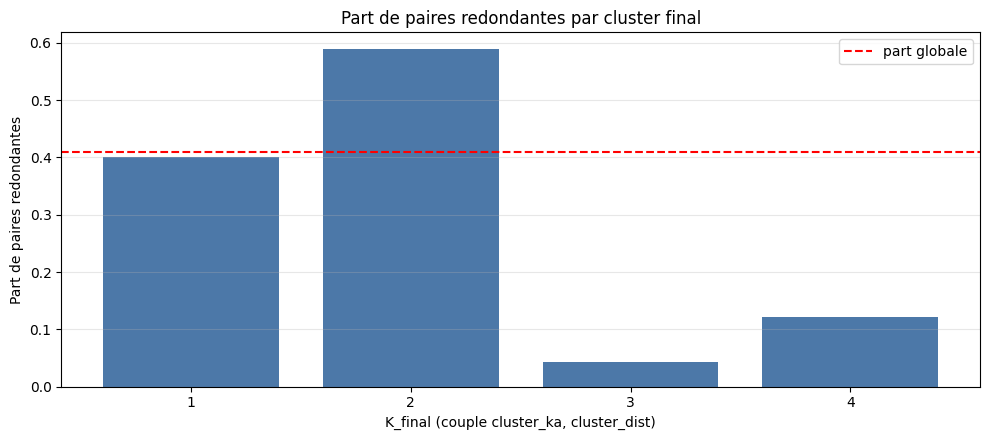

In [13]:
# ---- Ratio redondant / divergent par cluster final ----
Y_PATH = repo_root.parent / "Données" / "Y_train_clean.csv"   # à adapter
ID_COL = None                 # nom de la colonne d'identifiant de paire ; None = même ordre que les matrices
LABEL_COL = "Classification"           # colonne redondant/divergent
VAL_REDONDANT = 0
VAL_DIVERGENT = 1

Y = pd.read_csv(Y_PATH)
print(Y.head(), Y[LABEL_COL].value_counts(), sep="\n\n")

# Identifiants des paires, dans l'ordre des matrices
ids = pd.read_csv(PATHS["Ka"], index_col=0).index

if ID_COL is not None:
    Y = Y.set_index(ID_COL).reindex(ids)
    if Y[LABEL_COL].isna().any():
        print(f"Attention : {Y[LABEL_COL].isna().sum()} paires sans label")
else:
    assert len(Y) == N, f"Y a {len(Y)} lignes, les matrices {N}"
    Y = Y.reset_index(drop=True)

# Cluster mimiSBM -> couple attendu (appariement hongrois calculé plus haut)
mimisbm_vers_attendu = dict(zip(
    appariement["cluster_mimisbm"].astype(int),
    appariement["K_final_attendu"].astype(int),
))

df = pd.DataFrame({
    "K_final": [mimisbm_vers_attendu[c] for c in z_pred + 1],   # cluster mimiSBM renommé en K_final attendu
    "label": Y[LABEL_COL].to_numpy(),
})

ratio = (
    df.groupby("K_final")["label"]
    .agg(
        n="size",
        n_redondant=lambda s: (s == VAL_REDONDANT).sum(),
        n_divergent=lambda s: (s == VAL_DIVERGENT).sum(),
    )
)
ratio["ratio_red_div"] = (ratio["n_redondant"] / ratio["n_divergent"]).round(3)
ratio["part_redondant"] = (ratio["n_redondant"] / ratio["n"]).round(3)

# On rattache les couples (cluster_ka, cluster_dist) pour lire le tableau
ratio = couples.set_index("K_final")[["cluster_ka", "cluster_dist"]].join(ratio)
ratio.loc["global"] = [None, None, len(df),
                       (df["label"] == VAL_REDONDANT).sum(),
                       (df["label"] == VAL_DIVERGENT).sum(),
                       round((df["label"] == VAL_REDONDANT).sum() / (df["label"] == VAL_DIVERGENT).sum(), 3),
                       round((df["label"] == VAL_REDONDANT).mean(), 3)]
display(ratio)
ratio.to_csv(OUTPUT_DIR / "ratio_redondant_divergent.csv")

# Visualisation
r = ratio.drop("global")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(r.index.astype(str), r["part_redondant"], color="#4C78A8")
ax.axhline(ratio.loc["global", "part_redondant"], color="red", ls="--", label="part globale")
ax.set(xlabel="K_final (couple cluster_ka, cluster_dist)", ylabel="Part de paires redondantes",
       title="Part de paires redondantes par cluster final")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

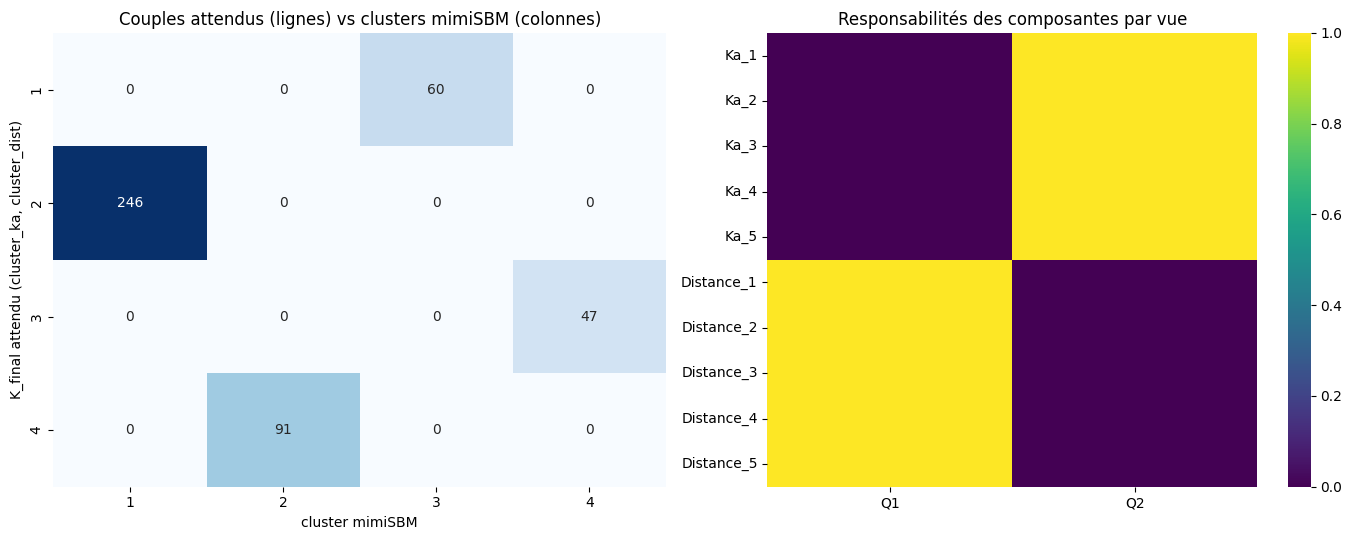

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(contingence, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set(title="Couples attendus (lignes) vs clusters mimiSBM (colonnes)",
            xlabel="cluster mimiSBM", ylabel="K_final attendu (cluster_ka, cluster_dist)")

sns.heatmap(modele.component_responsibilities_, cmap="viridis", ax=axes[1],
            yticklabels=noms_vues, xticklabels=["Q1", "Q2"], vmin=0, vmax=1)
axes[1].set(title="Responsabilités des composantes par vue")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "resultats_ka_distance.png", dpi=150)
plt.show()

appariement.to_csv(OUTPUT_DIR / "appariement_clusters.csv", index=False)

## Répétition sur plusieurs tirages de perturbation (optionnel)

Refait la simulation avec plusieurs graines pour obtenir la distribution de l'ARI.

,replicat,ARI_clusters,ARI_composantes,ELBO
mean,10.500,1.0,1.0,-50466.044
std,5.916,0.0,0.0,323.912
min,1.000,1.0,1.0,-51014.119
max,20.000,1.0,1.0,-49819.905


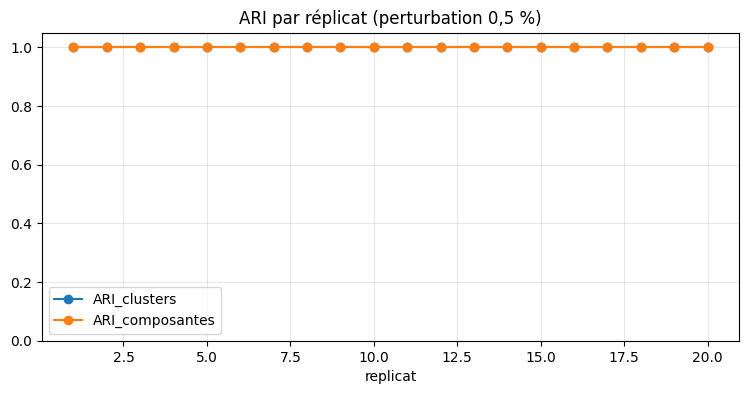

In [8]:
N_REPLICATS = 20
lignes = []
for r in range(N_REPLICATS):
    tenseur_r, _ = simuler_tenseur(labels_ref, N_COPIES, TAUX_PERTURBATION, seed=1000 + r)
    m = ajuster_meilleur_elbo(tenseur_r, K_VRAI, Q, seed0=100 * r)
    lignes.append({
        "replicat": r + 1,
        "ARI_clusters": adjusted_rand_score(z_vrai, m.cluster_responsibilities_.argmax(axis=1)),
        "ARI_composantes": adjusted_rand_score(w_vrai, m.component_responsibilities_.argmax(axis=1)),
        "ELBO": m.elbo_,
    })

replicats = pd.DataFrame(lignes)
replicats.to_csv(OUTPUT_DIR / "replicats_ari.csv", index=False)
display(replicats.describe().loc[["mean", "std", "min", "max"]].round(3))

replicats.plot(x="replicat", y=["ARI_clusters", "ARI_composantes"], marker="o", figsize=(9, 4))
plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.title("ARI par réplicat (perturbation 0,5 %)")
plt.show()

## 20 simulations de même manière que précédemment

In [9]:
from scipy.special import entr

N_SIMULATIONS = 20
K_CANDIDATS = range(2, 16)
Q_CANDIDATS = range(1, 11)
N_INIT_SIM = 2
MAX_ITER_SIM = 100
TOL_SIM = 1e-6
PRIORS_SIM = "jeffreys"

CRITERES = ("ILVB", "ICL_variationnel", "ICL_approx")


def calculer_scores_simulation(modele, N, V):
    """Calcule les critères de sélection pour un modèle ajusté."""
    ilvb = float(modele.elbo_)

    icl_variationnel = ilvb - (
        entr(modele.cluster_responsibilities_).sum()
        + entr(modele.component_responsibilities_).sum()
    )

    K, Q = modele.n_clusters, modele.n_components
    penalite = (
        0.5 * (K * (K + 1) / 2 * Q) * np.log(V * N * (N - 1) / 2)
        + 0.5 * (K - 1) * np.log(N)
        + 0.5 * (Q - 1) * np.log(V)
    )
    icl_approx = ilvb - penalite

    return {
        "ILVB": ilvb,
        "ICL_variationnel": icl_variationnel,
        "ICL_approx": icl_approx,
    }


res_select_simul_ka_dist = []
grilles_simulations = []

for numero_simulation in range(N_SIMULATIONS):
    seed_simulation = SEED + numero_simulation

    # Les clusters de référence et le mécanisme de perturbation restent inchangés.
    tenseur_sim, noms_vues_sim = simuler_tenseur(
        labels_ref=labels_ref,
        n_copies=N_COPIES,
        taux=TAUX_PERTURBATION,
        seed=seed_simulation,
    )

    N, _, V = tenseur_sim.shape
    print(
        f"Simulation {numero_simulation + 1}/{N_SIMULATIONS} "
        f": tenseur {tenseur_sim.shape}"
    )

    lignes_grille = []

    for K in K_CANDIDATS:
        if K > N:
            continue

        for Q in Q_CANDIDATS:
            if Q > V:
                continue

            meilleur_modele = None
            meilleur_elbo = -np.inf

            for init in range(N_INIT_SIM):
                seed_fit = (
                    50_000
                    + numero_simulation * 1_000_000
                    + K * 1_000
                    + Q * 100
                    + init
                )

                candidat = MimiSBM(
                    n_clusters=K,
                    n_components=Q,
                    clusters_prior=PRIORS_SIM,
                    components_prior=PRIORS_SIM,
                    adjacency_prior=PRIORS_SIM,
                    max_iter=MAX_ITER_SIM,
                    tol=TOL_SIM,
                    random_state=seed_fit,
                )

                try:
                    candidat.fit(tenseur_sim)
                except ValueError as exc:
                    if "Probabilities contain NaN" in str(exc):
                        continue
                    raise

                elbo = float(candidat.elbo_)
                if np.isfinite(elbo) and elbo > meilleur_elbo:
                    meilleur_modele = candidat
                    meilleur_elbo = elbo

            if meilleur_modele is None:
                raise RuntimeError(
                    f"Aucun ajustement valide pour la simulation "
                    f"{numero_simulation + 1}, K={K}, Q={Q}."
                )

            lignes_grille.append({
                "simulation": numero_simulation + 1,
                "K": K,
                "Q": Q,
                **calculer_scores_simulation(meilleur_modele, N, V),
            })

    grille = pd.DataFrame(lignes_grille)
    grilles_simulations.extend(lignes_grille)

    for critere in CRITERES:
        meilleur = grille.loc[grille[critere].idxmax()]

        res_select_simul_ka_dist.append({
            "simulation": numero_simulation + 1,
            "critere": critere,
            "K_selectionne": int(meilleur["K"]),
            "Q_selectionne": int(meilleur["Q"]),
            "score": float(meilleur[critere]),
        })


res_selection_simu = pd.DataFrame(res_select_simul_ka_dist)
grilles_simulations = pd.DataFrame(grilles_simulations)

res_selection_simu.to_csv(
    OUTPUT_DIR / "selection_K_Q_20_simulations_ka_distance.csv",
    index=False,
)
grilles_simulations.to_csv(
    OUTPUT_DIR / "grille_K_Q_20_simulations_ka_distance.csv",
    index=False,
)

res_selection_simu

Simulation 1/20 : tenseur (444, 444, 10)
Simulation 2/20 : tenseur (444, 444, 10)
Simulation 3/20 : tenseur (444, 444, 10)
Simulation 4/20 : tenseur (444, 444, 10)
Simulation 5/20 : tenseur (444, 444, 10)
Simulation 6/20 : tenseur (444, 444, 10)
Simulation 7/20 : tenseur (444, 444, 10)
Simulation 8/20 : tenseur (444, 444, 10)
Simulation 9/20 : tenseur (444, 444, 10)
Simulation 10/20 : tenseur (444, 444, 10)
Simulation 11/20 : tenseur (444, 444, 10)
Simulation 12/20 : tenseur (444, 444, 10)
Simulation 13/20 : tenseur (444, 444, 10)
Simulation 14/20 : tenseur (444, 444, 10)
Simulation 15/20 : tenseur (444, 444, 10)
Simulation 16/20 : tenseur (444, 444, 10)
Simulation 17/20 : tenseur (444, 444, 10)
Simulation 18/20 : tenseur (444, 444, 10)
Simulation 19/20 : tenseur (444, 444, 10)
Simulation 20/20 : tenseur (444, 444, 10)


,simulation,critere,K_selectionne,Q_selectionne,score
0,1,ILVB,15,6,-22546.312176
1,1,ICL_variationnel,15,6,-22546.312176
2,1,ICL_approx,9,4,-25353.895396
3,2,ILVB,14,7,-21646.731824
4,2,ICL_variationnel,14,7,-21646.731824
5,2,ICL_approx,13,3,-24842.390217
6,3,ILVB,13,4,-24010.410890
7,3,ICL_variationnel,13,4,-24010.410890
8,3,ICL_approx,12,4,-26283.880480
9,4,ILVB,14,7,-21217.899208


In [ ]:
# # Calculer ratio redondant divergent

# lab_ka, lab_dist = labels_ref["Ka"], labels_ref["Distance"]

# couples = (
#     pd.DataFrame({"cluster_ka": lab_ka + 1, "cluster_dist": lab_dist + 1})
#     .value_counts().rename("taille").reset_index()
#     .sort_values(["cluster_ka", "cluster_dist"]).reset_index(drop=True)
# )
# couples.insert(0, "K_final", np.arange(1, len(couples) + 1))
# K_VRAI = len(couples)
# display(couples)
# print(f"K attendu = {K_VRAI} couples non vides")

# # Cluster final attendu de chaque paire
# cle = {(r.cluster_ka, r.cluster_dist): r.K_final for r in couples.itertuples()}
# z_vrai = np.array([cle[(a + 1, d + 1)] for a, d in zip(lab_ka, lab_dist)]) - 1